# Deep Optimal Stopping for Bermudan Max-Call Options
## Part I — Learning the exercise policy and estimating a primal lower bound

**Author:** Georges Rolland  
**Reference:** Becker, Cheridito & Jentzen, *Deep Optimal Stopping*, Journal of Machine Learning Research, 20(74), 2019.

This notebook is an independent PyTorch reimplementation of the **primal side** of the Deep Optimal Stopping method on the symmetric Bermudan max-call benchmark studied by Becker et al. I focus on three questions:

1. How can an optimal stopping problem be rewritten as a sequence of binary stop/continue decisions?
2. How can neural networks learn those decisions directly from Monte Carlo paths?
3. Once a stopping policy is learned, how accurately does its out-of-sample value reproduce the lower-bound benchmark reported in the paper?

The notebook deliberately stops at the **lower bound**. The dual martingale construction, upper bound and variance-reduction methods are separate extensions because they answer a different question: not how good the learned policy is, but how far its value may still be from the true optimum.

The mathematical objective, augmented state representation, benchmark parameters, network width, Monte Carlo sampling logic and independent lower-bound evaluation follow the experiment described in the paper.


## 1. The pricing problem as optimal stopping

I consider a Bermudan max-call written on $d$ assets. Under the risk-neutral measure,

$$
S_t^i = S_0^i\exp\left[\left(r-\delta_i-\frac{1}{2}\sigma_i^2\right)t + \sigma_i W_t^i\right],
\qquad i=1,\ldots,d.
$$

Here $r$ is the continuously compounded risk-free rate, $\delta_i$ the dividend yield of asset $i$, $\sigma_i$ its volatility, and $W^i$ its Brownian driver. In the symmetric benchmark used below, all assets share the same $S_0$, $\delta$ and $\sigma$, with constant pairwise correlation $\rho$.

Exercise is allowed on an equally spaced grid $0=t_0<t_1<\cdots<t_N=T$. If I exercise at $t_n$, the time-0 discounted reward is

$$
g(n,S_{t_n}) = e^{-rt_n}\left(\max_{1\leq i\leq d}S_{t_n}^i-K\right)^+,
$$

where $K$ is the strike and $T$ the maturity. Writing $X_n=S_{t_n}$, the option value is therefore

$$
V_0 = \sup_{\tau\in\mathcal T}\mathbb E\left[g(\tau,X_\tau)\right],
$$

where $\mathcal T$ is the set of stopping times taking values on the exercise grid.

The key object is the **stopping policy**. At each exercise date, the decision is binary: exercise now or continue. Becker et al. approximate these date-specific decisions with feed-forward neural networks and learn them backward in time. A learned policy $\widehat\tau$ is admissible, so

$$
L = \mathbb E[g(\widehat\tau,X_{\widehat\tau})] \leq V_0.
$$

This is why evaluating the learned policy on a new independent Monte Carlo sample produces a **primal lower bound**.


## 2. Reproducible benchmark configuration

I reproduce the symmetric $d=5$, $S_0=100$ experiment in Table 1 of Becker et al.:

$$
r=5\%,\quad \delta=10\%,\quad \sigma=20\%,\quad \rho=0,\quad K=100,\quad T=3,\quad N=9.
$$

The paper reports a lower-bound estimate of **26.156** for this case, with the full primal-dual 95% pricing interval **[26.138, 26.174]**.

For training, the paper reports $3{,}000+d$ optimization steps and batches of 8,192 newly simulated paths. I preserve that simulation budget and perform a backward policy update at every training step. The lower bound is then estimated on $K_L=4{,}096{,}000$ independent paths, processed in chunks so that evaluation remains memory efficient.

A fixed random seed makes a run reproducible within a given software/hardware setup, although floating-point kernels can still lead to small cross-platform differences.


In [1]:
from dataclasses import dataclass
import math
import random
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from tqdm.auto import tqdm

import torch
import torch.nn as nn


@dataclass(frozen=True)
class ExperimentConfig:
    # Market and contract parameters: Becker et al. (2019), Table 1 benchmark.
    d: int = 5
    s0: float = 100.0
    strike: float = 100.0
    r: float = 0.05
    dividend: float = 0.10
    sigma: float = 0.20
    rho: float = 0.0
    maturity: float = 3.0
    n_steps: int = 9

    # Neural policy and optimization.
    hidden_width: int = 45          # d + 40 in the d=5 benchmark.
    train_steps: int = 3005         # 3,000 + d.
    train_batch_size: int = 8192
    learning_rate: float = 1e-3
    record_every: int = 10

    # Independent Monte Carlo evaluation.
    lower_bound_paths: int = 4_096_000
    eval_batch_size: int = 131_072
    diagnostic_paths: int = 200_000

    # Reproducibility.
    seed: int = 42

    # Published benchmark values used only for comparison after evaluation.
    paper_lower_bound: float = 26.156
    paper_price_ci_low: float = 26.138
    paper_price_ci_high: float = 26.174


cfg = ExperimentConfig()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
dtype = torch.float32


def set_seed(seed: int) -> None:
    """Seed Python, NumPy and PyTorch random number generators."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


set_seed(cfg.seed)
print(f"Device: {device}")
print(f"PyTorch: {torch.__version__}")

Device: cpu
PyTorch: 2.11.0+cpu


In [2]:
benchmark = pd.DataFrame(
    {
        "Parameter": ["d", "S0", "K", "r", "dividend", "sigma", "rho", "T", "N", "hidden width", "training steps", "batch size", "K_L"],
        "Value": [
            cfg.d, cfg.s0, cfg.strike, cfg.r, cfg.dividend, cfg.sigma, cfg.rho,
            cfg.maturity, cfg.n_steps, cfg.hidden_width, cfg.train_steps,
            cfg.train_batch_size, cfg.lower_bound_paths,
        ],
    }
)
display(benchmark)

,Parameter,Value
0,d,5.00
1,S0,100.00
2,K,100.00
3,r,0.05
4,dividend,0.10
5,sigma,0.20
6,rho,0.00
7,T,3.00
8,N,9.00
9,hidden width,45.00


## 3. Exact simulation of the multidimensional Black–Scholes model

Because the Black–Scholes transition is known in closed form, I do not need an Euler discretization. For $\Delta t=T/N$,

$$
S_{t_{n+1}}^i
=
S_{t_n}^i
\exp\left[
\left(r-\delta-\frac{\sigma^2}{2}\right)\Delta t
+\sigma\sqrt{\Delta t}\,Z_{n+1}^i
\right],
$$

where the Gaussian vector $Z_{n+1}$ has unit marginal variances and the prescribed cross-asset correlation $\rho$. The benchmark uses $\rho=0$, so the Brownian shocks are independent across assets.

A first numerical check compares the simulated terminal mean with the risk-neutral identity

$$
\mathbb E[S_T]=S_0e^{(r-\delta)T}.
$$

This check does not validate the stopping algorithm, but it verifies that the state process feeding the neural policy is simulated consistently with the model.


In [3]:
def equicorrelation_cholesky(d: int, rho: float, device: torch.device) -> torch.Tensor:
    """Cholesky factor of a d-dimensional equicorrelation matrix."""
    lower_bound = -1.0 / (d - 1) if d > 1 else -1.0
    if not (lower_bound < rho < 1.0):
        raise ValueError(f"rho must lie in ({lower_bound:.4f}, 1) for a positive-definite equicorrelation matrix.")

    corr = torch.full((d, d), rho, dtype=dtype, device=device)
    corr.fill_diagonal_(1.0)
    return torch.linalg.cholesky(corr)


def simulate_paths(n_paths: int, cfg: ExperimentConfig, device: torch.device) -> torch.Tensor:
    """
    Simulate exact Black-Scholes paths.

    Returns
    -------
    paths : torch.Tensor
        Shape (N+1, n_paths, d). The first slice is the deterministic initial state.
    """
    dt = cfg.maturity / cfg.n_steps
    drift = (cfg.r - cfg.dividend - 0.5 * cfg.sigma**2) * dt
    diffusion = cfg.sigma * math.sqrt(dt)

    z = torch.randn(cfg.n_steps, n_paths, cfg.d, device=device, dtype=dtype)

    if abs(cfg.rho) > 1e-12:
        chol = equicorrelation_cholesky(cfg.d, cfg.rho, device)
        z = torch.matmul(z, chol.T)

    log_returns = drift + diffusion * z
    log_relative_prices = torch.cumsum(log_returns, dim=0)

    future_prices = cfg.s0 * torch.exp(log_relative_prices)
    initial_prices = torch.full((1, n_paths, cfg.d), cfg.s0, device=device, dtype=dtype)
    return torch.cat([initial_prices, future_prices], dim=0)


def discounted_rewards(paths: torch.Tensor, cfg: ExperimentConfig) -> torch.Tensor:
    """Compute g(n, S_n) = exp(-r t_n) * (max_i S_n^i - K)^+ at every exercise date."""
    times = torch.linspace(0.0, cfg.maturity, cfg.n_steps + 1, device=paths.device, dtype=paths.dtype)
    intrinsic = torch.clamp(paths.max(dim=-1).values - cfg.strike, min=0.0)
    discounts = torch.exp(-cfg.r * times).unsqueeze(1)
    return discounts * intrinsic


def policy_state(prices_at_n: torch.Tensor, reward_at_n: torch.Tensor) -> torch.Tensor:
    """State Y_n = (X_n, g(n, X_n)) used by Becker et al. in the max-call experiment."""
    return torch.cat([prices_at_n, reward_at_n.unsqueeze(1)], dim=1)

,quantity,value
0,theoretical E[S_T],86.070798
1,mean simulated E[S_T],86.083298
2,relative error,0.000145


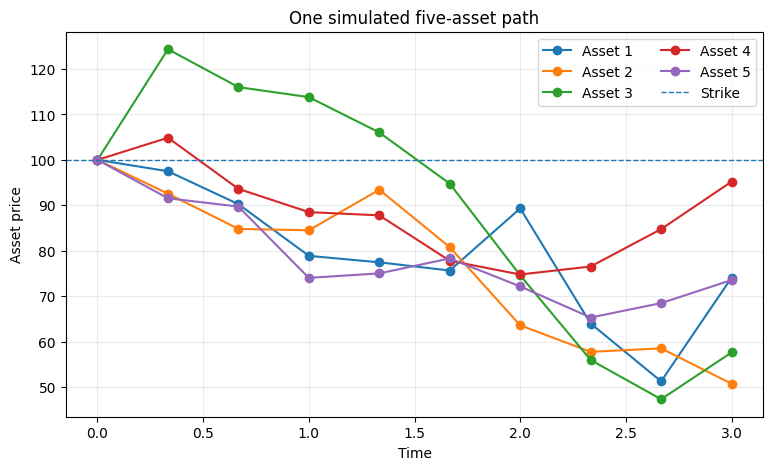

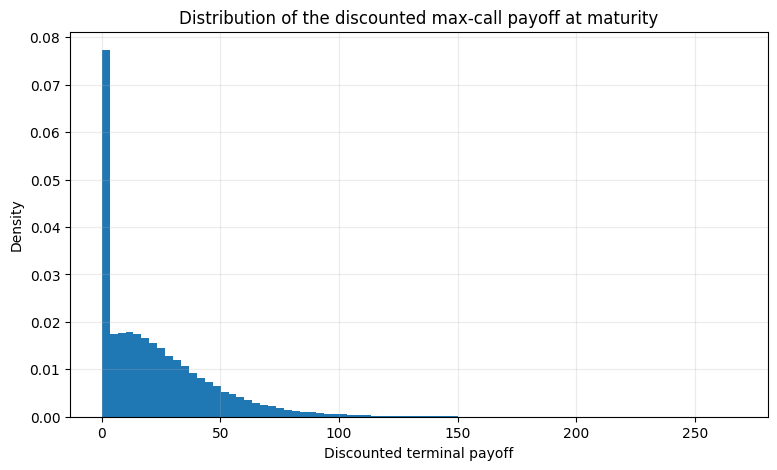

### Simulation check

The simulated terminal mean is **86.0833**, versus the analytical risk-neutral mean **86.0708**. The relative discrepancy is **0.015%**, which is consistent with Monte Carlo sampling error at this sample size.

In [4]:
# Simulation sanity check and first visual diagnostics.
set_seed(cfg.seed + 1)
check_paths = simulate_paths(100_000, cfg, device)
check_rewards = discounted_rewards(check_paths, cfg)

theoretical_terminal_mean = cfg.s0 * math.exp((cfg.r - cfg.dividend) * cfg.maturity)
empirical_terminal_means = check_paths[-1].mean(dim=0).detach().cpu().numpy()
relative_error = abs(empirical_terminal_means.mean() - theoretical_terminal_mean) / theoretical_terminal_mean

validation = pd.DataFrame(
    {
        "quantity": ["theoretical E[S_T]", "mean simulated E[S_T]", "relative error"],
        "value": [theoretical_terminal_mean, empirical_terminal_means.mean(), relative_error],
    }
)
display(validation)

sample = check_paths[:, 0, :].detach().cpu().numpy()
times = np.linspace(0.0, cfg.maturity, cfg.n_steps + 1)

plt.figure(figsize=(9, 5))
for asset in range(cfg.d):
    plt.plot(times, sample[:, asset], marker="o", linewidth=1.5, label=f"Asset {asset + 1}")
plt.axhline(cfg.strike, linestyle="--", linewidth=1.0, label="Strike")
plt.xlabel("Time")
plt.ylabel("Asset price")
plt.title("One simulated five-asset path")
plt.legend(ncol=2)
plt.grid(alpha=0.25)
plt.show()

terminal_rewards = check_rewards[-1].detach().cpu().numpy()
plt.figure(figsize=(9, 5))
plt.hist(terminal_rewards, bins=80, density=True)
plt.xlabel("Discounted terminal payoff")
plt.ylabel("Density")
plt.title("Distribution of the discounted max-call payoff at maturity")
plt.grid(alpha=0.25)
plt.show()

comment = (
    f"The simulated terminal mean is **{empirical_terminal_means.mean():.4f}**, versus the analytical "
    f"risk-neutral mean **{theoretical_terminal_mean:.4f}**. The relative discrepancy is "
    f"**{100 * relative_error:.3f}%**, which is consistent with Monte Carlo sampling error at this sample size."
)
display(Markdown("### Simulation check\n\n" + comment))

del check_paths, check_rewards
if torch.cuda.is_available():
    torch.cuda.empty_cache()

## 4. Neural stopping rule

At date $t_n$, suppose the downstream stopping rule $\tau_{n+1}$ is already available. Becker et al. optimize the soft decision $F^{\theta_n}(Y_n)\in(0,1)$ through

$$
\mathbb E\left[
 g(n,X_n)F^{\theta_n}(Y_n)
 +
 g(\tau_{n+1},X_{\tau_{n+1}})\left(1-F^{\theta_n}(Y_n)\right)
\right].
$$

The soft output is differentiable and can therefore be trained by gradient methods. The actual exercise policy is deterministic:

$$
f^{\theta_n}(Y_n)=\mathbf 1_{\{F^{\theta_n}(Y_n)\geq 1/2\}}.
$$

For the max-call experiment, Becker et al. augment the asset vector with the immediate discounted reward and report hidden widths $q_1=q_2=d+40$. For $d=5$, I therefore use the architecture

```text
Y_n = (S_n^1, ..., S_n^5, g_n)
            │
       BatchNorm
            │
       Linear(6, 45)
            │
     BatchNorm + ReLU
            │
      Linear(45, 45)
            │
     BatchNorm + ReLU
            │
       Linear(45, 1)
            │
         Sigmoid
            │
       soft stop score
```

Xavier initialization, batch normalization and Adam follow the training ingredients stated in the paper. Batch normalization replaces the ad-hoc per-batch standardization used in the earlier project notebook and gives the network a consistent train/evaluation transformation through its running statistics.

In [5]:
class StoppingNet(nn.Module):
    """Date-specific soft stopping rule F^theta_n : R^(d+1) -> (0, 1)."""

    def __init__(self, input_dim: int, hidden_width: int):
        super().__init__()
        self.input_bn = nn.BatchNorm1d(input_dim)
        self.fc1 = nn.Linear(input_dim, hidden_width)
        self.bn1 = nn.BatchNorm1d(hidden_width)
        self.fc2 = nn.Linear(hidden_width, hidden_width)
        self.bn2 = nn.BatchNorm1d(hidden_width)
        self.out = nn.Linear(hidden_width, 1)
        self.reset_parameters()

    def reset_parameters(self) -> None:
        for module in self.modules():
            if isinstance(module, nn.Linear):
                nn.init.xavier_uniform_(module.weight)
                nn.init.zeros_(module.bias)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        x = self.input_bn(x)
        x = torch.relu(self.bn1(self.fc1(x)))
        x = torch.relu(self.bn2(self.fc2(x)))
        return torch.sigmoid(self.out(x)).squeeze(-1)


input_dim = cfg.d + 1
example_net = StoppingNet(input_dim, cfg.hidden_width).to(device)
print(example_net)
print(f"Trainable parameters per exercise date: {sum(p.numel() for p in example_net.parameters() if p.requires_grad):,}")
del example_net

StoppingNet(
  (input_bn): BatchNorm1d(6, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (fc1): Linear(in_features=6, out_features=45, bias=True)
  (bn1): BatchNorm1d(45, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (fc2): Linear(in_features=45, out_features=45, bias=True)
  (bn2): BatchNorm1d(45, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (out): Linear(in_features=45, out_features=1, bias=True)
)
Trainable parameters per exercise date: 2,623


## 5. Backward policy optimization

The terminal decision is fixed: if the option has not been exercised earlier, it is exercised at $t_N$. I therefore initialize every path with

$$
\tau_N \equiv N.
$$

This point matters numerically. The continuation payoff at $t_{N-1}$ must be $g(N,X_N)$; initializing the stopping index to an earlier date would change the optimization problem itself.

I then perform repeated **backward sweeps**. Each training step generates a fresh Monte Carlo batch. Within that batch, the date-specific networks are updated from $N-1$ back to $1$. For each date, downstream decisions are treated as fixed when optimizing the current network, exactly matching the stop-versus-continuation objective above.

The training quantity plotted below is not a classification loss. It is the **estimated discounted reward of the soft stop/continue mixture**. The PyTorch loss is simply its negative because optimizers minimize by convention.

In [6]:
def train_stopping_policy(cfg: ExperimentConfig, device: torch.device):
    """
    Train date-specific stopping networks by repeated backward Monte Carlo sweeps.

    A fresh batch of Black-Scholes paths is generated at every outer training step.
    At each date n, the current network maximizes the soft mixture of immediate reward
    and the realized reward generated by the downstream hard stopping policy.
    """
    set_seed(cfg.seed)

    models = [None] * (cfg.n_steps + 1)
    optimizers = [None] * (cfg.n_steps + 1)

    for n in range(1, cfg.n_steps):
        model = StoppingNet(cfg.d + 1, cfg.hidden_width).to(device)
        models[n] = model
        optimizers[n] = torch.optim.Adam(model.parameters(), lr=cfg.learning_rate)

    history_rows = []
    path_indices = torch.arange(cfg.train_batch_size, device=device)

    start = time.perf_counter()
    progress = tqdm(range(cfg.train_steps), desc="Training stopping policy")

    for step in progress:
        paths = simulate_paths(cfg.train_batch_size, cfg, device)
        rewards = discounted_rewards(paths, cfg)

        # At maturity, exercise is mandatory if the contract is still alive.
        downstream_tau = torch.full(
            (cfg.train_batch_size,), cfg.n_steps, dtype=torch.long, device=device
        )

        # One backward sweep: n = N-1, ..., 1.
        for n in range(cfg.n_steps - 1, 0, -1):
            model = models[n]
            optimizer = optimizers[n]
            model.train()

            state_n = policy_state(paths[n], rewards[n])
            reward_now = rewards[n]
            reward_continue = rewards[downstream_tau, path_indices].detach()

            stop_score = model(state_n)
            soft_policy_reward = stop_score * reward_now + (1.0 - stop_score) * reward_continue
            objective = soft_policy_reward.mean()
            loss = -objective

            optimizer.zero_grad(set_to_none=True)
            loss.backward()
            optimizer.step()

            # The hard decision is detached: earlier dates optimize against a fixed downstream rule.
            with torch.no_grad():
                stop_now = stop_score >= 0.5
                downstream_tau = torch.where(
                    stop_now,
                    torch.full_like(downstream_tau, n),
                    downstream_tau,
                )

            if step % cfg.record_every == 0 or step == cfg.train_steps - 1:
                history_rows.append(
                    {
                        "step": step,
                        "date_index": n,
                        "time": n * cfg.maturity / cfg.n_steps,
                        "objective": float(objective.detach().cpu()),
                        "hard_stop_rate": float(stop_now.float().mean().cpu()),
                        "mean_soft_score": float(stop_score.detach().mean().cpu()),
                    }
                )

        if step % 100 == 0 or step == cfg.train_steps - 1:
            progress.set_postfix(
                objective_t1=f"{history_rows[-1]['objective']:.3f}",
                elapsed=f"{time.perf_counter() - start:.1f}s",
            )

    elapsed = time.perf_counter() - start
    for n in range(1, cfg.n_steps):
        models[n].eval()

    return models, pd.DataFrame(history_rows), elapsed

In [7]:
models, training_history, training_seconds = train_stopping_policy(cfg, device)
print(f"Training time: {training_seconds:.1f} seconds")

Training stopping policy:   0%|          | 0/3005 [00:00<?, ?it/s]

Training time: 443.6 seconds


### Training diagnostics

Because the optimization proceeds backward, each date solves a different economic problem. Near maturity, the network compares immediate exercise with only a short remaining continuation horizon. Earlier dates retain a larger set of future exercise opportunities.

I monitor the soft-policy objective separately for every exercise date. The curves are noisy because every update uses a newly simulated Monte Carlo batch. The relevant convergence signal is therefore not a perfectly smooth loss curve, but a reward objective that improves and then fluctuates around a stable level.

The objective at $t_1$ should **not** be interpreted as the final lower bound: it is an in-training soft-policy quantity. The lower bound is obtained only after freezing the hard policy and evaluating it on an independent sample.


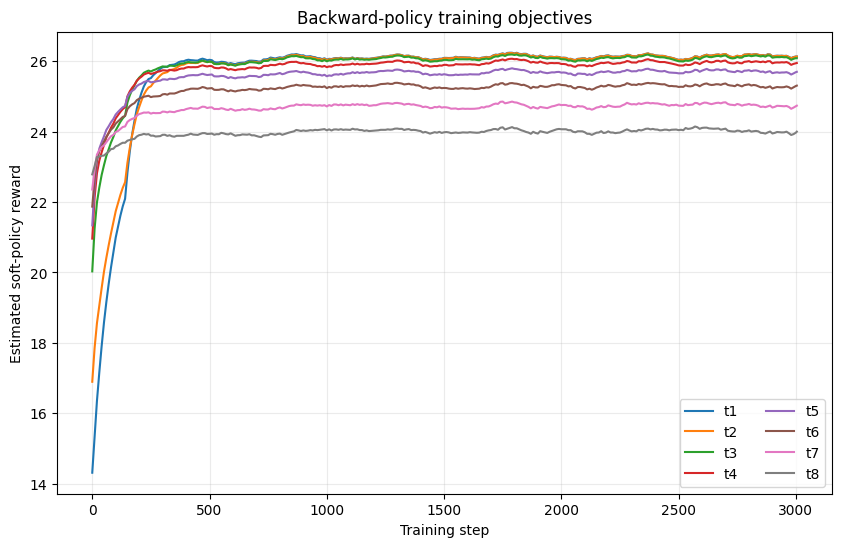

,date_index,time,mean_final_objective,mean_final_stop_rate,mean_final_soft_score
0,1,0.333333,26.172720,0.000000,0.000056
1,2,0.666667,26.169351,0.026001,0.027227
2,3,1.000000,26.127936,0.080481,0.081308
3,4,1.333333,25.998562,0.145483,0.146100
4,5,1.666667,25.757518,0.212085,0.212674
5,6,2.000000,25.369069,0.281104,0.281326
6,7,2.333333,24.768234,0.347375,0.348172
7,8,2.666667,24.015573,0.459546,0.460158


In [8]:
plt.figure(figsize=(10, 6))
for n in range(1, cfg.n_steps):
    subset = training_history[training_history["date_index"] == n].copy()
    smoothed = subset["objective"].rolling(window=15, min_periods=1).mean()
    plt.plot(subset["step"], smoothed, linewidth=1.5, label=f"t{n}")

plt.xlabel("Training step")
plt.ylabel("Estimated soft-policy reward")
plt.title("Backward-policy training objectives")
plt.legend(ncol=2)
plt.grid(alpha=0.25)
plt.show()

final_training_summary = (
    training_history.sort_values("step")
    .groupby("date_index", as_index=False)
    .tail(10)
    .groupby("date_index", as_index=False)
    .agg(
        mean_final_objective=("objective", "mean"),
        mean_final_stop_rate=("hard_stop_rate", "mean"),
        mean_final_soft_score=("mean_soft_score", "mean"),
    )
)
final_training_summary["time"] = final_training_summary["date_index"] * cfg.maturity / cfg.n_steps
display(final_training_summary[["date_index", "time", "mean_final_objective", "mean_final_stop_rate", "mean_final_soft_score"]])

**<u>Analysis:</u>**

The training objectives stabilize toward the end of the optimization despite the expected noise induced by newly simulated Monte Carlo batches at each update. The final soft-policy objective decreases from approximately **26.173** at the first exercise date to **24.016** near maturity.

This pattern is economically consistent with the backward structure of the stopping problem: starting the problem later removes earlier exercise opportunities and therefore reduces the attainable expected reward.

The objective associated with a single training date should not be interpreted as the option price itself. The final lower bound is obtained only after freezing the resulting hard stopping policy and evaluating it on an independent Monte Carlo sample.

## 6. Applying the learned hard stopping policy

Training uses the differentiable soft score $F^{\theta_n}$. Pricing uses the hard policy

$$
f^{\theta_n}(Y_n)=\mathbf 1_{\{F^{\theta_n}(Y_n)\ge 1/2\}}.
$$

I evaluate dates in chronological order and stop at the **first** exercise signal. Paths that never cross the threshold are exercised at maturity. For this benchmark, the time-0 intrinsic reward is zero and Becker et al. report that immediate exercise is never optimal, so the learned policy starts at $t_1$.

In [10]:
@torch.no_grad()
def apply_policy(models, paths: torch.Tensor, cfg: ExperimentConfig, collect_scores: bool = False):
    """Apply the hard first-hit stopping rule to a batch of simulated paths."""
    rewards = discounted_rewards(paths, cfg)
    n_paths = paths.shape[1]
    tau = torch.full((n_paths,), cfg.n_steps, dtype=torch.long, device=paths.device)

    score_matrix = None
    if collect_scores:
        score_matrix = torch.full(
            (cfg.n_steps + 1, n_paths), float("nan"), dtype=paths.dtype, device=paths.device
        )

    for n in range(1, cfg.n_steps):
        alive = tau == cfg.n_steps
        if not alive.any():
            break

        state_n = policy_state(paths[n], rewards[n])
        score = models[n](state_n)

        if collect_scores:
            score_matrix[n, alive] = score[alive]

        stop_now = alive & (score >= 0.5)
        tau[stop_now] = n

    indices = torch.arange(n_paths, device=paths.device)
    realized_rewards = rewards[tau, indices]
    return tau, realized_rewards, score_matrix

## 7. What exercise policy did the network learn?

Before estimating the final lower bound, I inspect the policy on an independent diagnostic sample. Three summaries are particularly informative:

- the unconditional distribution of stopping dates;
- the conditional exercise rate among contracts still alive at each date;
- a one-dimensional projection of the stopping score against $\max_i S_{t_n}^i$.

The last plot is **not** the full exercise boundary: the true state is six-dimensional here, $(S^1,\ldots,S^5,g)$. It is only an interpretable projection of the learned policy.

In [11]:
set_seed(cfg.seed + 20_000)
diagnostic_paths = simulate_paths(cfg.diagnostic_paths, cfg, device)
diagnostic_rewards = discounted_rewards(diagnostic_paths, cfg)
diagnostic_tau, diagnostic_realized_rewards, diagnostic_scores = apply_policy(
    models, diagnostic_paths, cfg, collect_scores=True
)

rows = []
for n in range(1, cfg.n_steps + 1):
    tau_cpu = diagnostic_tau
    alive = tau_cpu >= n
    exercise = tau_cpu == n
    alive_count = int(alive.sum().cpu())
    exercise_count = int(exercise.sum().cpu())

    if n < cfg.n_steps:
        mean_score_alive = float(torch.nanmean(diagnostic_scores[n]).cpu())
    else:
        mean_score_alive = 1.0

    rows.append(
        {
            "date_index": n,
            "time": n * cfg.maturity / cfg.n_steps,
            "survival_rate": alive_count / cfg.diagnostic_paths,
            "exercise_rate": exercise_count / cfg.diagnostic_paths,
            "conditional_exercise_rate": exercise_count / alive_count if alive_count else np.nan,
            "mean_soft_score_alive": mean_score_alive,
        }
    )

policy_stats = pd.DataFrame(rows)
display(policy_stats)

,date_index,time,survival_rate,exercise_rate,conditional_exercise_rate,mean_soft_score_alive
0,1,0.333333,1.000000,0.000000,0.000000,0.000053
1,2,0.666667,1.000000,0.023385,0.023385,0.024352
2,3,1.000000,0.976615,0.067565,0.069183,0.070059
3,4,1.333333,0.909050,0.091155,0.100275,0.101157
4,5,1.666667,0.817895,0.099015,0.121061,0.121714
5,6,2.000000,0.718880,0.103590,0.144099,0.144831
6,7,2.333333,0.615290,0.109680,0.178257,0.179472
7,8,2.666667,0.505610,0.119990,0.237317,0.239231
8,9,3.000000,0.385620,0.385620,1.000000,1.000000


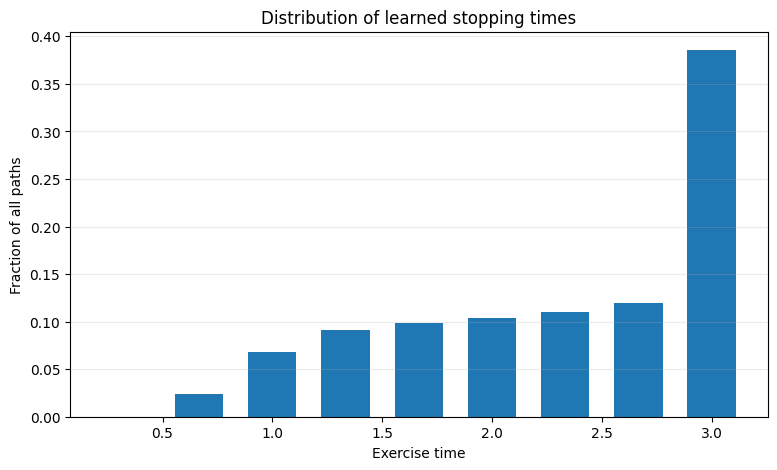

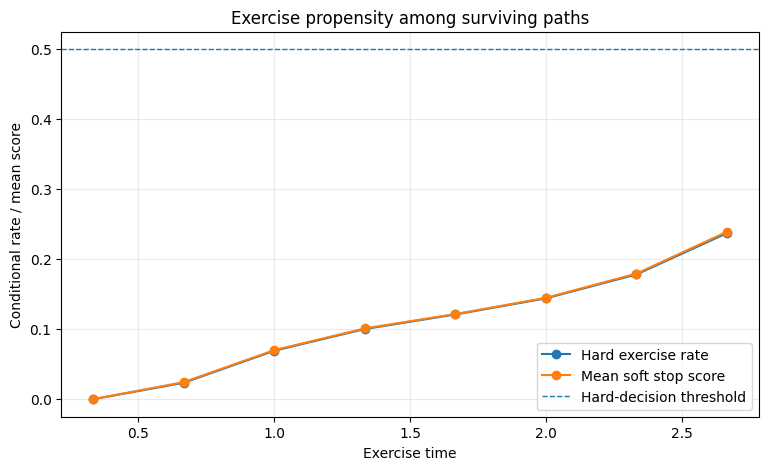

In [12]:
plt.figure(figsize=(9, 5))
plt.bar(policy_stats["time"], policy_stats["exercise_rate"], width=0.22)
plt.xlabel("Exercise time")
plt.ylabel("Fraction of all paths")
plt.title("Distribution of learned stopping times")
plt.grid(axis="y", alpha=0.25)
plt.show()

plt.figure(figsize=(9, 5))
pre_maturity = policy_stats[policy_stats["date_index"] < cfg.n_steps]
plt.plot(pre_maturity["time"], pre_maturity["conditional_exercise_rate"], marker="o", label="Hard exercise rate")
plt.plot(pre_maturity["time"], pre_maturity["mean_soft_score_alive"], marker="o", label="Mean soft stop score")
plt.axhline(0.5, linestyle="--", linewidth=1.0, label="Hard-decision threshold")
plt.xlabel("Exercise time")
plt.ylabel("Conditional rate / mean score")
plt.title("Exercise propensity among surviving paths")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

**<u>Analysis:</u>**

The learned policy exercises very few paths at the beginning of the contract and becomes progressively more aggressive as maturity approaches. Conditional on survival, the exercise rate increases from approximately **2.3%** at \(t=0.67\) to **23.7%** at the last exercise opportunity before maturity.

Overall, approximately **61.4%** of the diagnostic paths are exercised before maturity, while **38.6%** reach the terminal date. The policy therefore does not collapse to either immediate exercise or systematic continuation: it learns a genuinely non-trivial Bermudan stopping rule.

The close agreement between the average soft stopping scores and the corresponding hard exercise rates also suggests that most decisions are relatively decisive rather than concentrated near the \(0.5\) threshold.

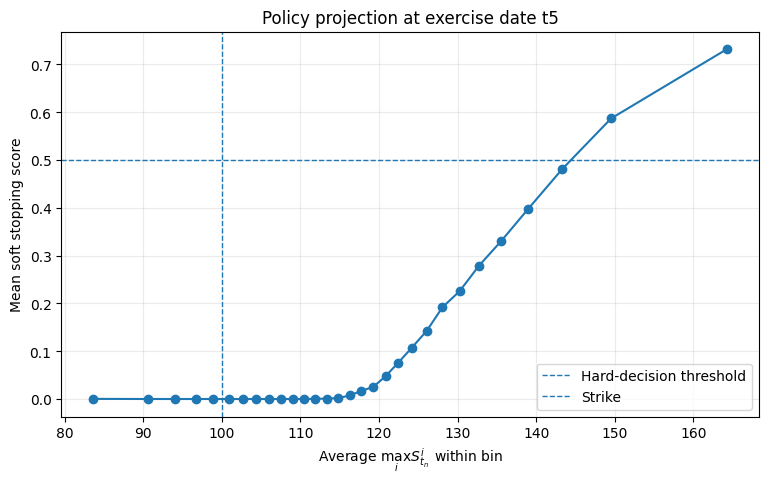

In [14]:
# One-dimensional projection of the learned policy at an intermediate exercise date.
projection_date = cfg.n_steps // 2 + 1
alive = diagnostic_tau >= projection_date
x = diagnostic_paths[projection_date, alive].max(dim=1).values.detach().cpu().numpy()
y = diagnostic_scores[projection_date, alive].detach().cpu().numpy()

projection = pd.DataFrame({"max_asset": x, "stop_score": y})
projection["bin"] = pd.qcut(projection["max_asset"], q=30, duplicates="drop")
binned = projection.groupby("bin", observed=True).agg(
    max_asset=("max_asset", "mean"),
    mean_stop_score=("stop_score", "mean"),
    observations=("stop_score", "size"),
).reset_index(drop=True)

plt.figure(figsize=(9, 5))
plt.plot(binned["max_asset"], binned["mean_stop_score"], marker="o")
plt.axhline(0.5, linestyle="--", linewidth=1.0, label="Hard-decision threshold")
plt.axvline(cfg.strike, linestyle="--", linewidth=1.0, label="Strike")
plt.xlabel(r"Average $\max_i S^i_{t_n}$ within bin")
plt.ylabel("Mean soft stopping score")
plt.title(f"Policy projection at exercise date t{projection_date}")
plt.legend()
plt.grid(alpha=0.25)
plt.show()



**<u>Analysis:</u>**

At this intermediate exercise date, the average stopping score crosses the \(0.5\) decision threshold when the strongest underlying asset is approximately **149.5**. The transition region is relatively broad, with mean stopping scores between \(0.25\) and \(0.75\) for values of the maximum asset roughly between **132.7 and 164.3**.

This graph must not be interpreted as the true exercise boundary. Although the immediate payoff only depends on \(\max_i S^i_t\), the continuation value depends on the full five-dimensional state. The figure is therefore a one-dimensional projection of the learned stopping surface.

The fact that the transition occurs well above the strike \(K=100\) also illustrates an important feature of American/Bermudan exercise: being in the money is not sufficient to justify immediate exercise when the remaining optionality still has value.

## 8. Independent Monte Carlo lower bound

The policy is now frozen. To avoid in-sample optimism, I evaluate it on a new independent set of paths. If the realized stopping index on path $k$ is $\widehat\tau^k$, the Monte Carlo estimator is

$$
\widehat L
=\frac{1}{K_L}\sum_{k=1}^{K_L}
 g(\widehat\tau^k,S^k_{t_{\widehat\tau^k}}).
$$

Conditional on the trained policy, this is an unbiased estimator of that policy's value. Because the policy is merely one admissible stopping rule, its expected value is a lower bound on the optimal Bermudan price.

The $4{,}096{,}000$ evaluation paths are generated independently from training and processed in chunks. I retain only the realized discounted rewards, so the full path tensor never has to reside in memory at once.

In [16]:
@torch.no_grad()
def estimate_lower_bound(models, cfg: ExperimentConfig, device: torch.device):
    """Estimate the learned policy value on K_L independent Monte Carlo paths."""
    set_seed(cfg.seed + 10_000)

    reward_chunks = []
    remaining = cfg.lower_bound_paths
    evaluated = 0
    start = time.perf_counter()

    progress = tqdm(total=cfg.lower_bound_paths, desc="Independent lower-bound evaluation", unit="paths")

    while remaining > 0:
        batch = min(cfg.eval_batch_size, remaining)
        paths = simulate_paths(batch, cfg, device)
        _, realized_rewards, _ = apply_policy(models, paths, cfg, collect_scores=False)

        reward_chunks.append(realized_rewards.detach().cpu().numpy().astype(np.float32, copy=False))
        remaining -= batch
        evaluated += batch
        progress.update(batch)

    progress.close()
    rewards = np.concatenate(reward_chunks)

    estimate = float(rewards.mean(dtype=np.float64))
    sample_std = float(rewards.std(ddof=1, dtype=np.float64))
    standard_error = sample_std / math.sqrt(len(rewards))
    mc_ci = (estimate - 1.96 * standard_error, estimate + 1.96 * standard_error)
    elapsed = time.perf_counter() - start

    return {
        "estimate": estimate,
        "sample_std": sample_std,
        "standard_error": standard_error,
        "mc_ci_95": mc_ci,
        "n_paths": len(rewards),
        "elapsed_seconds": elapsed,
        "rewards": rewards,
    }


lower_result = estimate_lower_bound(models, cfg, device)
lower_result_summary = pd.DataFrame(
    {
        "metric": ["Lower-bound estimate", "Sample standard deviation", "Monte Carlo standard error", "95% MC CI for learned-policy value", "Evaluation paths", "Evaluation time (s)"],
        "value": [
            lower_result["estimate"],
            lower_result["sample_std"],
            lower_result["standard_error"],
            str(tuple(round(x, 6) for x in lower_result["mc_ci_95"])),
            lower_result["n_paths"],
            lower_result["elapsed_seconds"],
        ],
    }
)
display(lower_result_summary)

Independent lower-bound evaluation:   0%|          | 0/4096000 [00:00<?, ?paths/s]

,metric,value
0,Lower-bound estimate,26.124706
1,Sample standard deviation,19.419132
2,Monte Carlo standard error,0.009595
3,95% MC CI for learned-policy value,"(26.1059, 26.143512)"
4,Evaluation paths,4096000
5,Evaluation time (s),20.763032


### Monte Carlo convergence of the lower-bound estimator

A valid policy does not guarantee a numerically precise estimate of its value unless the independent evaluation sample is sufficiently large. I therefore inspect the cumulative mean as the number of trial paths grows. The curve should stabilize as sampling error contracts at the usual $K_L^{-1/2}$ Monte Carlo rate.

,evaluation_paths,lower_bound_estimate,mc_standard_error,ci_low,ci_high
0,10000,26.305799,0.193476,25.926586,26.685011
1,20000,26.264829,0.136678,25.996941,26.532718
2,50000,26.249801,0.086677,26.079914,26.419687
3,100000,26.192906,0.061462,26.072440,26.313373
4,200000,26.144691,0.043524,26.059385,26.229997
5,500000,26.165018,0.027493,26.111132,26.218904
6,1000000,26.133172,0.019439,26.095071,26.171273
7,2000000,26.136528,0.013741,26.109596,26.163461
8,4096000,26.124706,0.009595,26.105900,26.143512


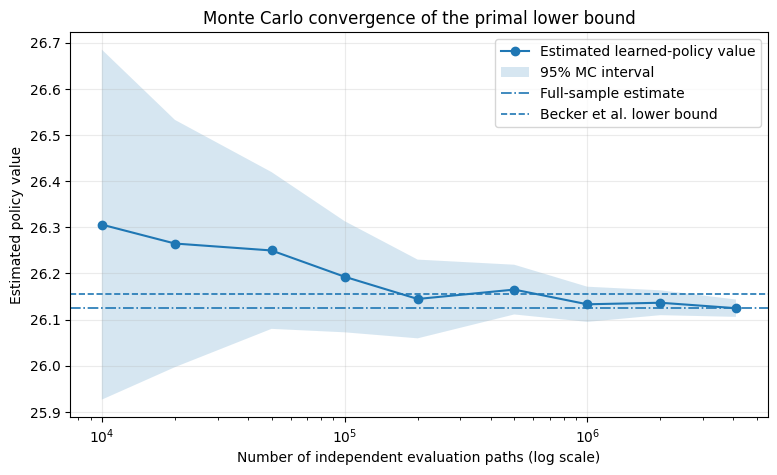


### Reading the Monte Carlo convergence

With only **10,000** evaluation paths, the estimate is **26.3058** and still carries visibly more
sampling uncertainty. As the independent sample grows, the confidence band contracts at the expected Monte Carlo
rate and the cumulative estimate settles at **26.124706**.

At the full sample size, the Monte Carlo standard error is **0.009595**.
The move from the penultimate checkpoint to the final estimate is **0.011822**, which is small relative
to the payoff scale. This separates two sources of error cleanly: as the evaluation sample grows, valuation noise contracts.
Whether the remaining benchmark gap is small or large is assessed explicitly in the comparison section below.


In [17]:
rewards = lower_result["rewards"].astype(np.float64, copy=False)
cumulative_sum = np.cumsum(rewards, dtype=np.float64)
cumulative_sq_sum = np.cumsum(rewards**2, dtype=np.float64)

candidate_sizes = np.array([
    10_000, 20_000, 50_000, 100_000, 200_000, 500_000,
    1_000_000, 2_000_000, cfg.lower_bound_paths,
])
candidate_sizes = np.unique(candidate_sizes[candidate_sizes <= len(rewards)])

cum_sum_n = cumulative_sum[candidate_sizes - 1]
cum_sq_sum_n = cumulative_sq_sum[candidate_sizes - 1]
cumulative_means = cum_sum_n / candidate_sizes

# Unbiased sample variance and Monte Carlo standard error at each checkpoint.
sample_vars = (cum_sq_sum_n - candidate_sizes * cumulative_means**2) / (candidate_sizes - 1)
checkpoint_se = np.sqrt(np.maximum(sample_vars, 0.0) / candidate_sizes)
checkpoint_low = cumulative_means - 1.96 * checkpoint_se
checkpoint_high = cumulative_means + 1.96 * checkpoint_se

convergence_table = pd.DataFrame(
    {
        "evaluation_paths": candidate_sizes,
        "lower_bound_estimate": cumulative_means,
        "mc_standard_error": checkpoint_se,
        "ci_low": checkpoint_low,
        "ci_high": checkpoint_high,
    }
)
display(convergence_table)

plt.figure(figsize=(9, 5))
plt.plot(candidate_sizes, cumulative_means, marker="o", label="Estimated learned-policy value")
plt.fill_between(candidate_sizes, checkpoint_low, checkpoint_high, alpha=0.18, label="95% MC interval")
plt.axhline(lower_result["estimate"], linestyle="-.", linewidth=1.2, label="Full-sample estimate")
plt.axhline(cfg.paper_lower_bound, linestyle="--", linewidth=1.2, label="Becker et al. lower bound")
plt.xscale("log")
plt.xlabel("Number of independent evaluation paths (log scale)")
plt.ylabel("Estimated policy value")
plt.title("Monte Carlo convergence of the primal lower bound")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

first_n = int(candidate_sizes[0])
first_estimate = float(cumulative_means[0])
last_estimate = float(cumulative_means[-1])
last_se = float(checkpoint_se[-1])

if len(candidate_sizes) >= 2:
    penultimate_gap = abs(float(cumulative_means[-2]) - last_estimate)
else:
    penultimate_gap = float("nan")

mc_text = f"""
### Reading the Monte Carlo convergence

With only **{first_n:,}** evaluation paths, the estimate is **{first_estimate:.4f}** and still carries visibly more
sampling uncertainty. As the independent sample grows, the confidence band contracts at the expected Monte Carlo
rate and the cumulative estimate settles at **{last_estimate:.6f}**.

At the full sample size, the Monte Carlo standard error is **{last_se:.6f}**.
The move from the penultimate checkpoint to the final estimate is **{penultimate_gap:.6f}**, which is small relative
to the payoff scale. This separates two sources of error cleanly: as the evaluation sample grows, valuation noise contracts.
Whether the remaining benchmark gap is small or large is assessed explicitly in the comparison section below.
"""
display(Markdown(mc_text))


**<u>Analysis:</u>**

The convergence plot illustrates the importance of using a sufficiently large independent evaluation sample. With only **10,000** paths, the estimated policy value is about **26.306**, whereas the estimate progressively stabilizes around **26.125** as the number of paths increases.

Using the complete sample of **4,096,000** independent trajectories, the lower-bound estimate is **26.124706** with a Monte Carlo standard error of only **0.009595**.

The shrinking confidence interval confirms that the remaining difference with the benchmark is no longer primarily driven by Monte Carlo evaluation noise. The dominant residual source of discrepancy is instead the learned stopping policy itself and the randomness associated with its optimization.

## 9. Comparison with Becker et al. (2019)

The comparison below uses the $d=5$, $S_0=100$ row of Table 1. The paper reports

- lower bound: **26.156**;
- upper bound: **26.162**;
- point estimate: **26.159**;
- primal-dual 95% pricing interval: **[26.138, 26.174]**.

Only the first number is reproduced directly in this notebook. The upper bound and pricing interval require the dual martingale construction and belong to the next stage of the project.

In [18]:
ours = lower_result["estimate"]
se = lower_result["standard_error"]
gap = ours - cfg.paper_lower_bound
relative_gap = gap / cfg.paper_lower_bound
gap_in_own_se = gap / se

comparison = pd.DataFrame(
    {
        "Quantity": ["Lower bound", "d", "S0", "K", "r", "dividend", "sigma", "rho", "T", "N"],
        "Becker et al.": [cfg.paper_lower_bound, 5, 100, 100, 0.05, 0.10, 0.20, 0.0, 3.0, 9],
        "This implementation": [ours, cfg.d, cfg.s0, cfg.strike, cfg.r, cfg.dividend, cfg.sigma, cfg.rho, cfg.maturity, cfg.n_steps],
    }
)
display(comparison)

abs_relative_gap = abs(relative_gap)
if abs_relative_gap <= 0.002:
    reproduction_sentence = (
        f"The independently trained policy reproduces the published lower bound within "
        f"**{100 * abs_relative_gap:.3f}%**, which I regard as a close numerical reproduction of the benchmark."
    )
elif abs_relative_gap <= 0.005:
    reproduction_sentence = (
        f"The estimate is within **{100 * abs_relative_gap:.3f}%** of the published lower bound. "
        "The benchmark is reproduced at the correct scale, with a modest residual policy gap."
    )
else:
    reproduction_sentence = (
        f"The estimate differs from the published lower bound by **{100 * abs_relative_gap:.3f}%**. "
        "The residual gap is large enough that I would not regard this run as a close numerical reproduction; "
        "additional policy-optimization diagnostics would be warranted."
    )

paper_lb_inside_our_mc_ci = (
    lower_result["mc_ci_95"][0] <= cfg.paper_lower_bound <= lower_result["mc_ci_95"][1]
)
pricing_interval_overlap = not (
    lower_result["mc_ci_95"][1] < cfg.paper_price_ci_low
    or lower_result["mc_ci_95"][0] > cfg.paper_price_ci_high
)

if paper_lb_inside_our_mc_ci:
    uncertainty_sentence = (
        "The published lower-bound estimate lies inside the 95% Monte Carlo interval for my frozen policy, so the "
        "observed numerical difference is compatible with evaluation noise at this resolution."
    )
else:
    overlap_note = (
        " The interval for my learned-policy value still overlaps the lower edge of the paper's full primal-dual "
        "pricing interval." if pricing_interval_overlap else ""
    )
    uncertainty_sentence = (
        "The published lower-bound estimate lies outside the 95% Monte Carlo interval for my frozen policy. "
        "Therefore, my own evaluation noise alone does not explain the full difference; the residual gap is more "
        "naturally attributed to policy optimization, implementation/training randomness, and the paper's own "
        "finite-sample estimation uncertainty." + overlap_note
    )

comparison_text = f"""
### Numerical interpretation

I obtain an out-of-sample lower-bound estimate of **{ours:.6f}**, with Monte Carlo standard error
**{se:.6f}**. Becker et al. report **{cfg.paper_lower_bound:.3f}** for the same benchmark, giving a difference
of **{gap:+.6f}** ({100 * relative_gap:+.3f}%).

{reproduction_sentence}

{uncertainty_sentence}

Measured only against the standard error of my frozen-policy evaluation, the difference is
**{gap_in_own_se:+.2f}** standard errors. This ratio is not a hypothesis test against the paper because the published
estimate has its own training and Monte Carlo randomness; it simply confirms that my final evaluation sample is
large enough for policy quality, rather than valuation noise, to be the main remaining numerical issue.

The distinction between **policy error** and **Monte Carlo error** is essential. The standard error above quantifies
how accurately I value the learned admissible policy. It does not quantify the distance between that policy and the
unknown optimal stopping rule. That optimality gap requires the dual upper bound.
"""
display(Markdown(comparison_text))


,Quantity,Becker et al.,This implementation
0,Lower bound,26.156,26.124706
1,d,5.000,5.000000
2,S0,100.000,100.000000
3,K,100.000,100.000000
4,r,0.050,0.050000
5,dividend,0.100,0.100000
6,sigma,0.200,0.200000
7,rho,0.000,0.000000
8,T,3.000,3.000000
9,N,9.000,9.000000



### Numerical interpretation

I obtain an out-of-sample lower-bound estimate of **26.124706**, with Monte Carlo standard error
**0.009595**. Becker et al. report **26.156** for the same benchmark, giving a difference
of **-0.031294** (-0.120%).

The independently trained policy reproduces the published lower bound within **0.120%**, which I regard as a close numerical reproduction of the benchmark.

The published lower-bound estimate lies outside the 95% Monte Carlo interval for my frozen policy. Therefore, my own evaluation noise alone does not explain the full difference; the residual gap is more naturally attributed to policy optimization, implementation/training randomness, and the paper's own finite-sample estimation uncertainty. The interval for my learned-policy value still overlaps the lower edge of the paper's full primal-dual pricing interval.

Measured only against the standard error of my frozen-policy evaluation, the difference is
**-3.26** standard errors. This ratio is not a hypothesis test against the paper because the published
estimate has its own training and Monte Carlo randomness; it simply confirms that my final evaluation sample is
large enough for policy quality, rather than valuation noise, to be the main remaining numerical issue.

The distinction between **policy error** and **Monte Carlo error** is essential. The standard error above quantifies
how accurately I value the learned admissible policy. It does not quantify the distance between that policy and the
unknown optimal stopping rule. That optimality gap requires the dual upper bound.


**<u>Analysis:</u>**

The learned policy produces an out-of-sample lower-bound estimate of **26.124706**, compared with **26.156** reported by Becker et al. for the same benchmark configuration.

The absolute difference is approximately **-0.0313**, corresponding to a relative discrepancy of only **0.12%**. This provides a close numerical reproduction of the published primal result using an independent PyTorch implementation and independently trained stopping policies.

The published lower bound lies slightly above the 95% Monte Carlo confidence interval associated with the frozen policy. Since the evaluation standard error is only **0.009595**, the remaining discrepancy cannot be explained by Monte Carlo valuation noise alone.

This distinction is important: the Monte Carlo standard error measures how accurately I value the learned policy, not how close that policy is to the unknown optimal stopping rule. Quantifying the latter requires the dual martingale upper bound.

## 10. What this experiment establishes

This experiment illustrates the central idea of Deep Optimal Stopping: a high-dimensional stopping problem can be attacked directly at the **policy level** rather than by first approximating the entire continuation-value surface.

The workflow is:

1. simulate the Markov state under the pricing measure;
2. represent each exercise decision by a differentiable neural score;
3. train stop/continue decisions backward against realized downstream rewards;
4. threshold the soft score to obtain an admissible first-hit stopping rule;
5. freeze the policy and value it on an independent Monte Carlo sample.

The resulting number is economically meaningful before any dual construction: it is the expected discounted payoff of a concrete feasible exercise strategy and therefore a lower bound on the true Bermudan price.

The diagnostics add a second layer of information. They show whether the training objectives stabilize, how the exercise intensity evolves through time, and how the learned stopping score reacts to the state. These checks do not prove optimality, but they make the learned policy interpretable rather than treating the neural network as a black-box price generator.

A lower bound alone still cannot certify near-optimality. A poor admissible policy remains a mathematically valid lower bound. The natural continuation is therefore the dual side of Becker et al.: construct a martingale-based upper bound, combine both sides into a pricing interval, and only then study how variance-reduction methods affect the efficiency of the dual estimator.

**<u>Final result:</u>**

For the \(d=5\) symmetric Bermudan max-call benchmark, the independently trained policy produces a lower bound of **26.124706**, compared with **26.156** in Becker et al., corresponding to a relative difference of approximately **0.12%**.

The exercise diagnostics show a non-degenerate stopping policy: approximately **61.4%** of paths are exercised before expiry while **38.6%** reach maturity. Together with the stable training objectives and the Monte Carlo convergence analysis, these results provide a consistent reproduction of the primal Deep Optimal Stopping methodology.

The lower bound alone cannot certify optimality. The natural next step is therefore the dual martingale construction of Becker et al., which provides an upper bound and allows the remaining optimality gap to be quantified.


## Reference

Becker, S., Cheridito, P., & Jentzen, A. (2019). **Deep Optimal Stopping**. *Journal of Machine Learning Research*, 20(74), 1–25.  
JMLR paper: https://www.jmlr.org/papers/v20/18-232.html